# Do UFC judges favor the champion?

**ECON 5200 Final Project, Milestone 1: Part 2 (the decision, the design, and the data).**

Every number in the proposal is printed by a cell below. The data table is built by `scripts/build_table.py`
from the raw files in `data/raw/`.

**How to read this notebook:** each code cell has a short note above it saying what it does, and comments inside it
explaining each step. Run the cells from top to bottom.

## Part 0: Setup

Load the tools we use. Nothing to change here.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("Setup complete.")

Setup complete.


## Part 2: The Decision, the Design, and the Data (Milestone 1)

### Research design

- **Client and decision:** a state athletic commission that assigns and trains judges for UFC title fights. It will
  decide whether to add champion-bias training and scorecard audits for title bouts.
- **Decides it:** a champion premium of **+0.10 in vote share** (0.3 of one judge's vote per decision) beyond what
  in-fight performance explains. This is my own judgment, written before estimating the DiD.
- **Causal question:** does holding the UFC title cause judges to score a fighter's close decisions more favorably,
  holding in-fight performance fixed, and by how much?
- **Why prediction is not enough:** champions win about three of four title decisions, but champions are also the
  better fighters. A model of who wins would credit the title with what skill explains.
- **Design and estimand:** staggered difference-in-differences at the fighter-fight level. The estimand is the average
  effect on the treated: fighters, after their first undisputed title win.
- **Who is treated:** fighters who win a UFC title. The count is printed below.
- **The comparison:** the same fighters before their first title win, and fighters who never held a title.
- **Key assumption:** parallel trends in performance-adjusted judge vote share. Without the title, treated fighters'
  adjusted vote share would have moved like that of fighters who never won a title.
- **How you will check it:** an event study of the decisions before the title win; a placebo title date.
- **The threat you worry about most:** title shots go to fighters on strong runs. If judges also scored those runs
  more generously than performance explains, the pre-period is inflated and mean reversion after the title would make
  the DiD estimate **too small** (even negative). Figure 1 suggests this is happening. The opposite threat, unmeasured
  quality gains as champion (damage, aggression), would make the estimate **too large**.

### Load the data

**What this cell does:** reads the table of fighter-fights (two rows per decision, one per fighter) and the sample counts.

**Where are the files?** If you opened the whole repo (cloned or uploaded it), leave `BASE` as an empty string.
If you only have this notebook in Colab, set `BASE` to your repo's raw GitHub link, for example
`"https://raw.githubusercontent.com/YOUR-USERNAME/YOUR-REPO/main/"` (keep the slash at the end).

In [2]:
BASE = ""   # leave empty if the data folder is next to this notebook

# One row per fighter per decision fight
ff = pd.read_csv(BASE + "data/processed/fighter_fights.csv", parse_dates=["date", "title_win_date"])

# A small file with the sample counts, saved by the build script
funnel = pd.read_json(BASE + "data/processed/sample_funnel.json", typ="series", convert_dates=False)

print(ff.shape)
ff.head(3)

(8248, 30)


,fight_url,date,event,location,weightclass,fighter,opponent,won,method,scheduled,...,d_total_kd,d_total_sub_att,rounds_fought,dob,reach_in,vote_share,title_win_date,ever_champ,post_title,age
0,http://ufcstats.com/fight-details/07ea5460ba2f...,2026-11-21,UFC Fight Night: Prochazka vs. Stirling,"Doha, Qatar",Featherweight Bout,Aljamain Sterling,Kevin Vallejos,0,Unanimous,3 Rnd (5-5-5),...,NaN,NaN,NaN,NaN,NaN,0.0,2021-03-06,1,1,NaN
1,http://ufcstats.com/fight-details/07ea5460ba2f...,2026-11-21,UFC Fight Night: Prochazka vs. Stirling,"Doha, Qatar",Featherweight Bout,Kevin Vallejos,Aljamain Sterling,1,Unanimous,3 Rnd (5-5-5),...,NaN,NaN,NaN,NaN,NaN,1.0,NaT,0,0,NaN
2,http://ufcstats.com/fight-details/739aaa5e3a1e...,2026-11-21,UFC Fight Night: Prochazka vs. Stirling,"Doha, Qatar",Lightweight Bout,Dan Hooker,Brian Ortega,1,Unanimous,3 Rnd (5-5-5),...,NaN,NaN,NaN,NaN,NaN,1.0,NaT,0,0,NaN


### Missing values and the sample rule

**What this cell does:** prints how many fights we start with and how many we keep. We keep decisions that have a winner
(draws are dropped) and that we could match to fight-level performance numbers (strikes, takedowns, and so on).

In [3]:
# The columns that measure in-fight performance (fighter minus opponent)
perf = ["d_total_sig_landed", "d_total_td_success", "d_total_ctrl_seconds", "d_total_kd", "d_total_sub_att"]

# How many fights at each step (these counts were saved by the build script)
print("UFC events in the results file:", funnel["ufc_events"], "(", funnel["first_date"], "to", funnel["last_date"], ")")
print("UFC fights:", funnel["ufc_fights"])
print("  ending in a decision:", funnel["decisions_all"])
print("  with a winner (draws dropped):", funnel["decisions_with_winner"])
print("  matched to fight-level performance:", funnel["decisions_matched_to_performance"])
print("Undisputed title bouts:", funnel["title_bouts_undisputed"],
      "| champion identified in:", funnel["title_bouts_with_incumbent"],
      "| interim title bouts (not used as treatment):", funnel["title_bouts_interim"])

# Drop the rows with no performance numbers
fights_before = ff["fight_url"].nunique()
ff = ff.dropna(subset=perf)
fights_after = ff["fight_url"].nunique()

print()
print("Latest fight with performance data:", ff["date"].max().date())
print("Dropped", fights_before - fights_after, "decisions with no performance match.")
print("Kept", fights_after, "decisions =", len(ff), "fighter-fights.")
print()
print("Missing values in other columns:")
print(ff[["age", "reach_in", "min_card_margin"]].isna().sum())

UFC events in the results file: 798 ( 1994-03-11 to 2026-11-21 )
UFC fights: 9040
  ending in a decision: 4189
  with a winner (draws dropped): 4124
  matched to fight-level performance: 4032
Undisputed title bouts: 371 | champion identified in: 322 | interim title bouts (not used as treatment): 30

Latest fight with performance data: 2026-08-08
Dropped 82 decisions with no performance match.
Kept 4032 decisions = 8064 fighter-fights.

Missing values in other columns:
age                 17
reach_in           376
min_card_margin    106
dtype: int64


### Table 1: treated fighters against the comparison group

**What this cell does:** compares the two groups *before any title win*. "Treated" are fighters who later won a title
(their fights before the win). "Comparison" are fighters who never won one.

In [4]:
# The variables to compare
cols = ["vote_share", "won", "d_total_sig_landed", "d_total_td_success", "d_total_ctrl_seconds", "d_total_kd", "age"]

# Keep only fights before a fighter's first title win (post_title == 0)
before = ff[ff["post_title"] == 0]

# Split into the two groups
treated = before[before["ever_champ"] == 1]
comparison = before[before["ever_champ"] == 0]

# Average of each variable in each group
table1 = pd.DataFrame({"Treated": treated[cols].mean(), "Comparison": comparison[cols].mean()})
table1["Difference"] = table1["Treated"] - table1["Comparison"]
table1 = table1.round(3)

# Add a row with the number of fighter-fights in each group
table1.loc["N (fighter-fights)"] = [len(treated), len(comparison), np.nan]
table1

,Treated,Comparison,Difference
vote_share,0.781,0.478,0.303
won,0.814,0.479,0.335
d_total_sig_landed,19.286,-1.347,20.633
d_total_td_success,1.178,-0.084,1.262
d_total_ctrl_seconds,121.269,-9.187,130.456
d_total_kd,0.098,-0.007,0.104
age,28.847,30.366,-1.519
N (fighter-fights),409.000,7254.000,NaN


In [5]:
# How many fighters are in each group?
champs_only = ff[ff["ever_champ"] == 1]
n_treated = champs_only["fighter"].nunique()

# Treated fighters with at least one decision before AND one after the title win
by_fighter = champs_only.groupby("fighter")["post_title"].agg(["min", "max"])
both_sides = ((by_fighter["min"] == 0) & (by_fighter["max"] == 1)).sum()

n_never = ff[ff["ever_champ"] == 0]["fighter"].nunique()
n_after = ff["post_title"].sum()

print("Treated fighters with a decision in the sample:", n_treated)
print("  with decisions both before and after the title win:", both_sides)
print("Comparison fighters (never held a title):", n_never)
print("Decision fighter-fights after a first title win:", n_after)

Treated fighters with a decision in the sample: 106
  with decisions both before and after the title win: 78
Comparison fighters (never held a title): 1988
Decision fighter-fights after a first title win: 401


### Figure 1: judge vote share around a fighter's first title win

**What this cell does, in three steps:**
1. Work out how much of each fighter's judge vote share is *not* explained by how they fought (strikes, takedowns, etc.).
   The leftover is the "adjusted vote share". A positive number means judges favored the fighter more than the numbers predict.
2. For fighters who won a title, number their decisions around the title win: -1 is the last decision before it,
   +1 is the first decision after it.
3. Average the adjusted vote share at each position and plot it.

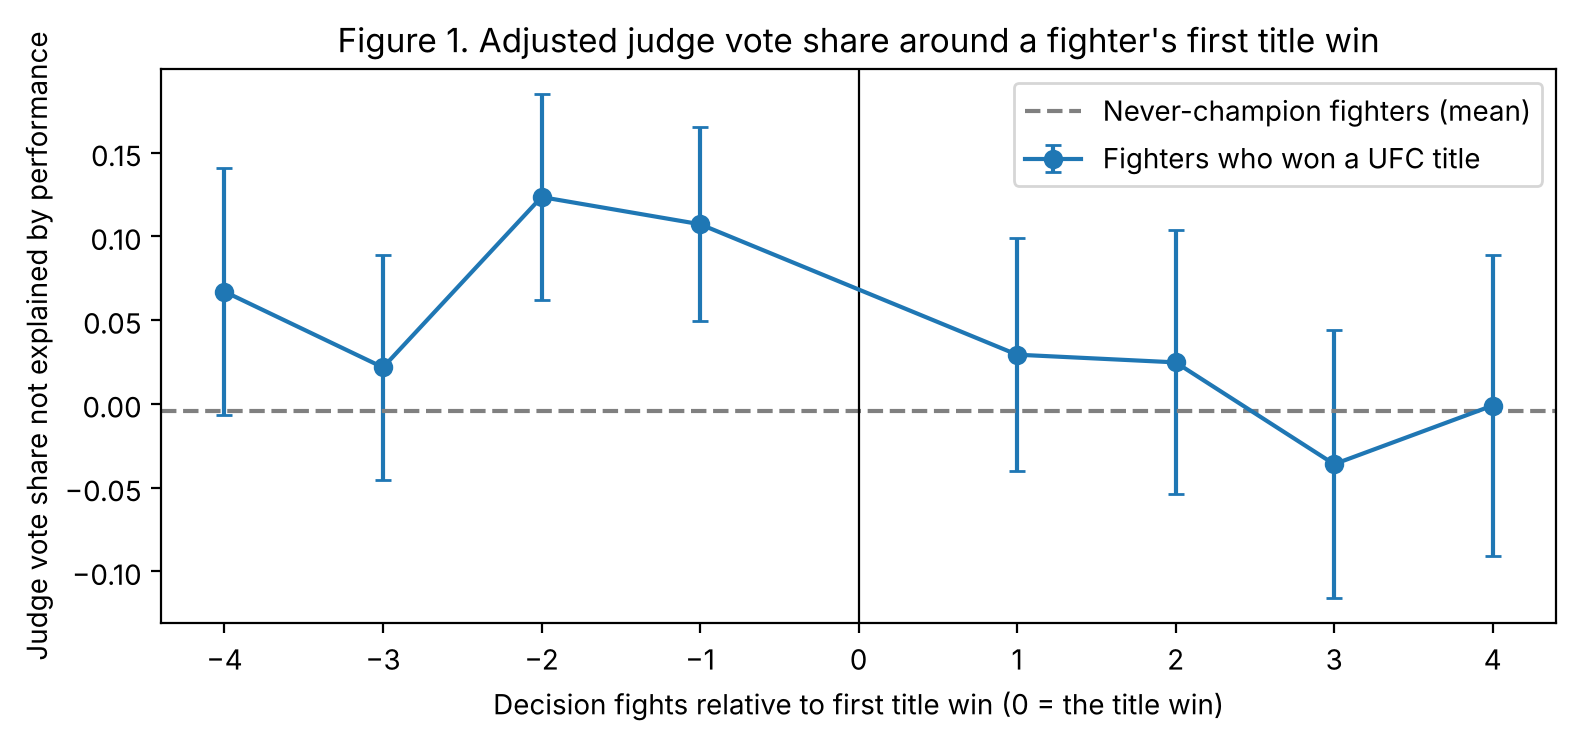

       mean    sem  count     ci
rel                             
-4.0  0.067  0.038     44  0.074
-3.0  0.022  0.034     59  0.067
-2.0  0.123  0.031     77  0.061
-1.0  0.107  0.030     94  0.058
 1.0  0.029  0.035     90  0.070
 2.0  0.025  0.040     71  0.079
 3.0 -0.036  0.041     60  0.080
 4.0 -0.001  0.046     50  0.090


In [6]:
# Step 1: adjusted vote share = what in-fight performance does not explain
formula = ("vote_share ~ d_total_sig_landed + d_total_td_success + d_total_ctrl_seconds"
           " + d_total_kd + d_total_sub_att")
model = smf.ols(formula, data=ff).fit()
ff["adj_vote_share"] = model.resid

# Step 2: number each treated fighter's decisions around the title win
champs = ff[ff["ever_champ"] == 1].sort_values(["fighter", "date"]).copy()
champs["rel"] = np.nan

for name, rows in champs.groupby("fighter"):
    before_rows = rows.index[rows["post_title"] == 0]   # decisions before the title win
    after_rows = rows.index[rows["post_title"] == 1]    # decisions after the title win
    champs.loc[before_rows, "rel"] = -np.arange(len(before_rows), 0, -1)   # ..., -2, -1
    champs.loc[after_rows, "rel"] = np.arange(1, len(after_rows) + 1)      # 1, 2, ...

# Step 3: average at each position from -4 to +4, with a 95% confidence interval
near = champs[champs["rel"].between(-4, 4)]
stats = near.groupby("rel")["adj_vote_share"].agg(["mean", "sem", "count"])
stats["ci"] = 1.96 * stats["sem"]

# For comparison: the average for fighters who never won a title
never_mean = ff[ff["ever_champ"] == 0]["adj_vote_share"].mean()

# Draw the figure
plt.figure(figsize=(9, 3.6))
plt.errorbar(stats.index, stats["mean"], yerr=stats["ci"], fmt="o-", capsize=3,
             label="Fighters who won a UFC title")
plt.axhline(never_mean, color="gray", linestyle="--", label="Never-champion fighters (mean)")
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Decision fights relative to first title win (0 = the title win)")
plt.ylabel("Judge vote share not explained by performance")
plt.title("Figure 1. Adjusted judge vote share around a fighter's first title win")
plt.legend()
plt.savefig("figures/figure1.png", dpi=150, bbox_inches="tight")
plt.show()

print(stats.round(3))

### Key EDA finding

**What this cell does:** looks only at title fights where we know who the champion was. It compares the champion's share of
the judges' votes with the challenger's, first as raw averages and then after holding in-fight performance fixed.
This is a comparison inside title fights, **not** the difference-in-differences estimate.

In [7]:
# Title fights where we know who the champion was
title = ff[(ff["is_title"]) & (ff["incumbent_champ"].notna())]
n_fights = title["fight_url"].nunique()

# Raw averages: share of the judges' votes for the champion and for the challenger
champ_share = title[title["i_am_champ"] == 1]["vote_share"].mean()
challenger_share = title[title["i_am_champ"] == 0]["vote_share"].mean()

# Share of these decisions that were not unanimous (split or majority)
champ_rows = title[title["i_am_champ"] == 1]
not_unanimous = (champ_rows["method"] != "Unanimous").mean()

# Regression: does being champion add vote share after holding performance fixed?
# Each fight appears twice (champion and challenger), so we cluster the standard errors by fight.
formula = ("vote_share ~ i_am_champ + d_total_sig_landed + d_total_td_success"
           " + d_total_ctrl_seconds + d_total_kd + d_total_sub_att")
fight_id = pd.factorize(title["fight_url"])[0]
fit = smf.ols(formula, data=title).fit(cov_type="cluster", cov_kwds={"groups": fight_id})
est = fit.params["i_am_champ"]
se = fit.bse["i_am_champ"]

print("Title decisions with an identified champion:", n_fights)
print("Champion's average share of the judges' votes:  ", round(champ_share, 3))
print("Challenger's average share of the judges' votes:", round(challenger_share, 3))
print("Share of these decisions that were not unanimous:", round(not_unanimous * 100, 1), "%")
print()
print("Champion premium after holding performance fixed:", round(est, 3), "(SE", round(se, 3), ")")
print("95% confidence interval:", round(est - 1.96 * se, 3), "to", round(est + 1.96 * se, 3))
print("Our threshold for acting was +0.10.")
print()
print(fit.summary().tables[1])

Title decisions with an identified champion: 127
Champion's average share of the judges' votes:   0.735
Challenger's average share of the judges' votes: 0.255
Share of these decisions that were not unanimous: 19.7 %

Champion premium after holding performance fixed: 0.257 (SE 0.063 )
95% confidence interval: 0.134 to 0.38
Our threshold for acting was +0.10.

                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept                0.3663      0.032     11.616      0.000       0.305       0.428
i_am_champ               0.2568      0.063      4.095      0.000       0.134       0.380
d_total_sig_landed       0.0036      0.001      6.492      0.000       0.003       0.005
d_total_td_success       0.0103      0.007      1.372      0.170      -0.004       0.025
d_total_ctrl_seconds     0.0002    6.8e-05      3.309      0.001    9.17e-05       0.000
d_total_kd      

### A concern the design will have to handle

**What this cell does:** reads two warning signs off the data. (1) Figure 1 does not look like parallel trends: the
adjusted vote share is higher just before the title win than after it. (2) After a title win, fights change in kind
(more title fights, more five-round fights).

In [8]:
# Fights after a first title win, and treated fighters' fights before it
after_win = ff[ff["post_title"] == 1]
before_win = ff[(ff["ever_champ"] == 1) & (ff["post_title"] == 0)]

# Average adjusted vote share (from Figure 1) in three windows
means = stats["mean"]
early = means.loc[[-4, -3]].mean()        # 4 and 3 decisions before the title win
late = means.loc[[-2, -1]].mean()         # the 2 decisions just before
after = means.loc[[1, 2, 3, 4]].mean()    # the 4 decisions after

# Simple before-and-after change for all treated rows (NOT the DiD estimate: no comparison group)
mean_before = before_win["adj_vote_share"].mean()
mean_after = after_win["adj_vote_share"].mean()

# Share of fights that are title fights, and share scheduled for five rounds
title_share_after = after_win["is_title"].mean()
five_after = after_win["scheduled"].str.startswith("5").mean()
five_before = before_win["scheduled"].str.startswith("5").mean()

print("Adjusted vote share, 4 and 3 decisions before the title win:", round(early, 3))
print("Adjusted vote share, 2 decisions just before the title win: ", round(late, 3))
print("Adjusted vote share, 4 decisions after the title win:       ", round(after, 3))
print("Before-after change over all rows:", round(mean_before, 3), "->", round(mean_after, 3),
      "= change of", round(mean_after - mean_before, 3))
print()
print("After a first title win, share of decisions that are title fights:", round(title_share_after * 100, 1), "%")
print("Scheduled for five rounds: after the win", round(five_after * 100, 1), "% vs before", round(five_before * 100, 1), "%")

Adjusted vote share, 4 and 3 decisions before the title win: 0.044
Adjusted vote share, 2 decisions just before the title win:  0.115
Adjusted vote share, 4 decisions after the title win:        0.004
Before-after change over all rows: 0.065 -> 0.006 = change of -0.06

After a first title win, share of decisions that are title fights: 37.2 %
Scheduled for five rounds: after the win 52.6 % vs before 23.2 %


**Reading the output:** the adjusted vote share is higher in the decisions just before the title win than after it, so
the pre-period looks inflated. Title shots follow strong runs, so a before-after comparison would be biased **too small**.
Unmeasured damage and tougher opponents push the other way (**too large**). The planned checks are an event study with
fighter fixed effects and a control for opponent strength.